# ML sobre las features (árbol de decisión → selección → baseline y otros modelos)

Orden del notebook:
1. Carga de `features_completes/features_train.csv` / `features_val.csv`.
2. **Árbol de decisión** para ver qué features son más útiles (y si esa lista es estable entre folds).
3. Selección de las top-K features. **Se hace dentro de cada fold de la validación cruzada** (no antes),
   para que las métricas no salgan infladas.
4. Baseline (regresión logística) y otros modelos, con **todas** las features y con las **top-K**.
5. Ablación por familias (forma / color / textura de la lesión y color / textura de la imagen entera).
6. Evaluación final en **val** (solo una vez, sin ajustar nada con ella).

Etiqueta: `label` (nevus = 0, others = 1). Se excluyen `name`, `class`, `subtype` (delata la clase) y `qc_*`.

Familias de features: `shape_`, `color_`, `tex_` (solo dentro de la lesión) y `gcolor_`, `gtex_` (imagen entera, sin máscara).

In [7]:
import os
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

try:
    from xgboost import XGBClassifier
except Exception as e:      # ImportError, o versiones mezcladas de conda/pip (ValueError)
    import sys
    XGBClassifier = None
    print(f"AVISO: no se puede importar xgboost -> se omite XGBoost\n"
          f"  error: {type(e).__name__}: {e}\n  python del kernel: {sys.executable}")

warnings.filterwarnings("ignore")

# ---------------- Configuración ----------------
# raíz del proyecto: el notebook está en ml/, así funciona igual en el ordenador de cada una
ROOT = Path.cwd().parent if Path.cwd().name == "ml" else Path.cwd()
# ROOT = Path(r"C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG")    # o fíjala a mano
assert (ROOT / "features_binary").exists(), f"ROOT incorrecta: {ROOT} (fíjala a mano arriba)"

TRAIN_CSV = ROOT / "features_binary" / "features_train.csv"
VAL_CSV   = ROOT / "features_binary" / "features_val.csv"
OUT_DIR   = ROOT / "ml" / "ml_results_completes2"     # carpeta nueva, para no pisar los resultados anteriores
K_FEATURES = 30
CV_FOLDS = 5
SEED = 42
N_JOBS = max(1, (os.cpu_count() or 1) - 2)          # todos los cores disponibles menos 2
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"ROOT: {ROOT}\ncores: {os.cpu_count()} -> N_JOBS = {N_JOBS}")

ROOT: C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG
cores: 28 -> N_JOBS = 26


## 1. Carga de datos

In [8]:
tr, va = pd.read_csv(TRAIN_CSV), pd.read_csv(VAL_CSV)

PREFIXES = ("shape_", "color_", "tex_", "gcolor_", "gtex_")
FEATS = [c for c in tr.columns if c.startswith(PREFIXES)]
assert FEATS == [c for c in va.columns if c.startswith(PREFIXES)], "train y val tienen columnas distintas"

Xtr, ytr = tr[FEATS].replace([np.inf, -np.inf], np.nan), tr["label"].values
Xva, yva = va[FEATS].replace([np.inf, -np.inf], np.nan), va["label"].values
family = lambda c: c.split("_")[0]

print(f"train: {Xtr.shape}  (others = {ytr.mean():.1%})   val: {Xva.shape}  (others = {yva.mean():.1%})")
print("features por familia:", pd.Series([family(c) for c in FEATS]).value_counts().to_dict())
print("NaN en features: train", int(Xtr.isna().sum().sum()), "| val", int(Xva.isna().sum().sum()))

skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
FAM_COLOR = {"shape": "#1f77b4", "color": "#d62728", "tex": "#2ca02c",
             "gcolor": "#ff9896", "gtex": "#98df8a"}

train: (15195, 420)  (others = 49.2%)   val: (3796, 420)  (others = 49.1%)
features por familia: {'tex': 95, 'gtex': 95, 'color': 83, 'shape': 76, 'gcolor': 71}
NaN en features: train 0 | val 0


## 2. Árbol de decisión: ¿qué features son más útiles?

Un árbol poco profundo (`max_depth=5`) es fácil de interpretar. Su importancia de cada feature es la reducción
total de impureza (Gini) que consigue al dividir con ella.
Aviso: **un solo árbol es inestable** (cambia bastante según los datos), por eso también miramos si el ranking
se repite en cada fold.

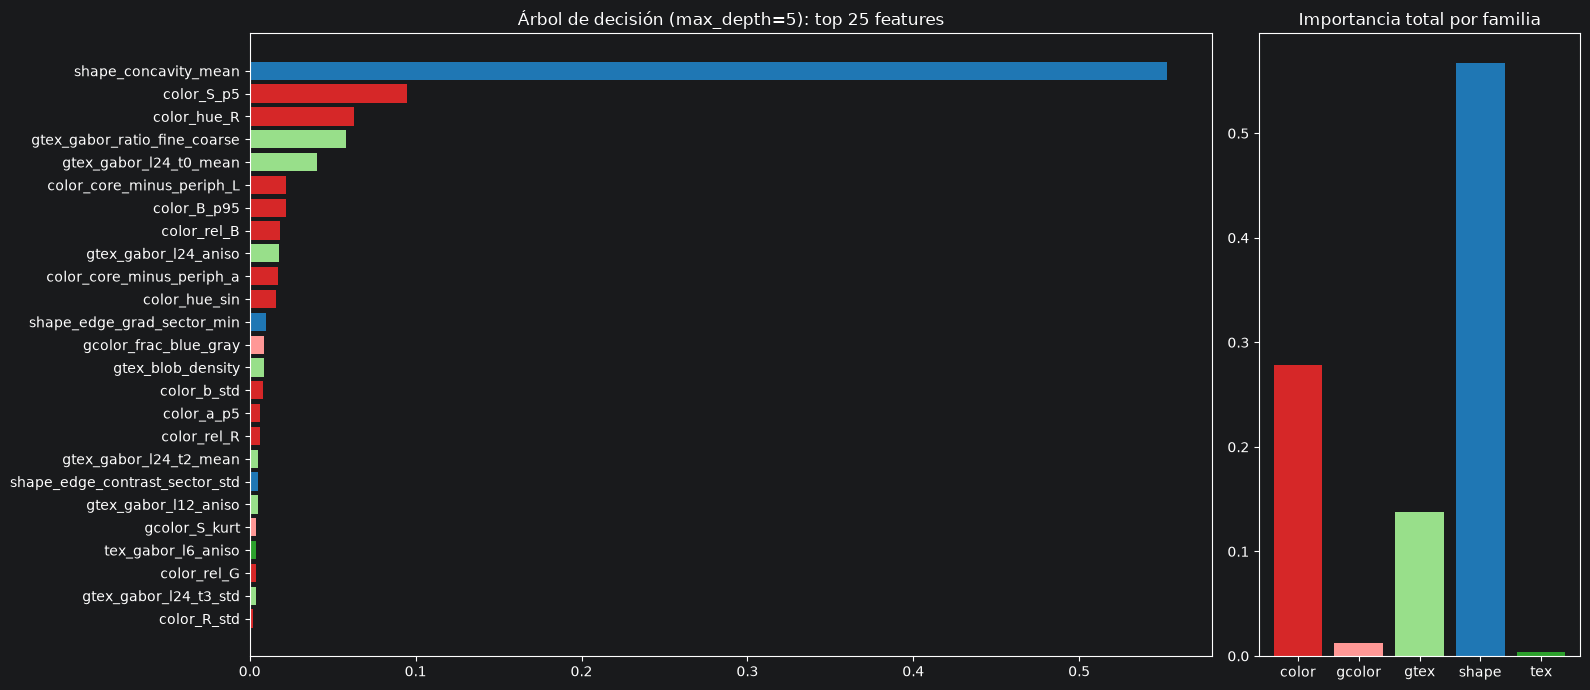

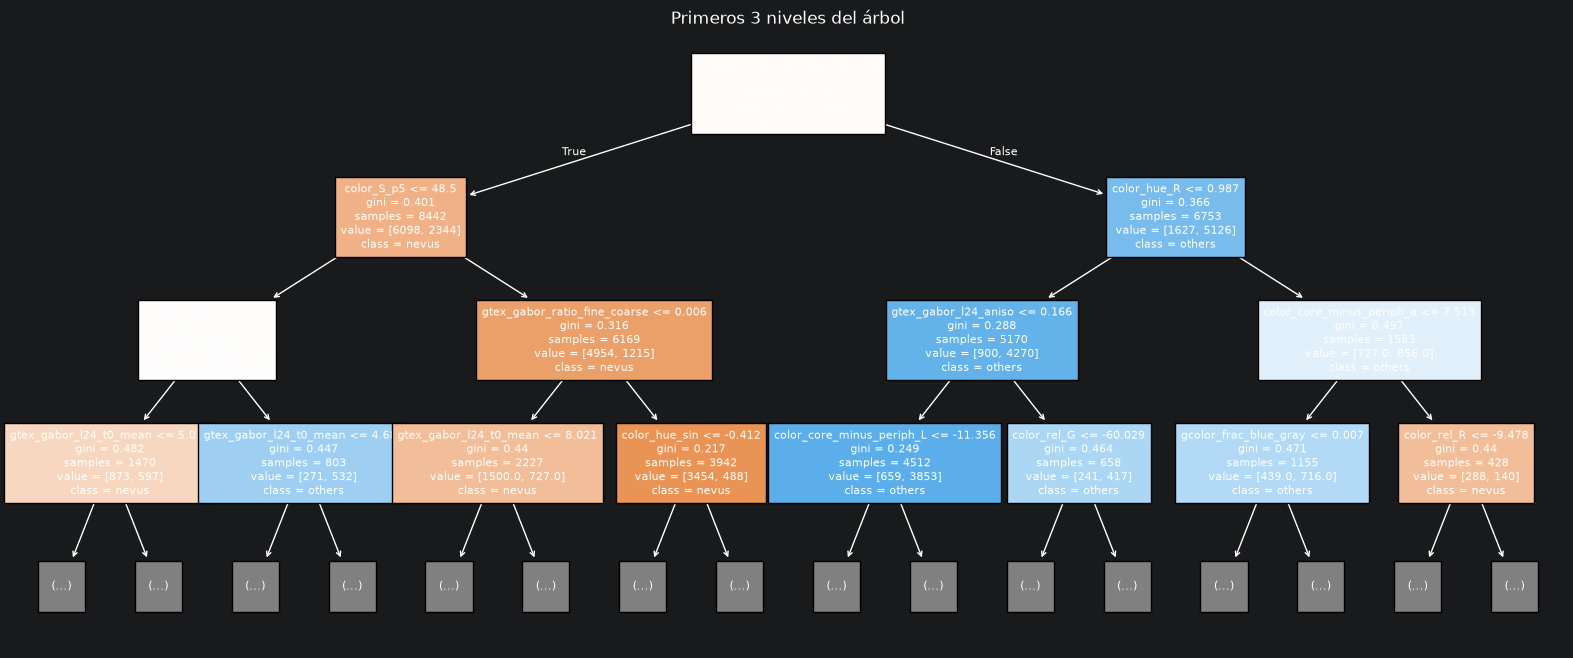

In [9]:
imp = SimpleImputer(strategy="median").fit(Xtr)
Xtr_i = pd.DataFrame(imp.transform(Xtr), columns=FEATS)

tree = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED).fit(Xtr_i, ytr)
imp_tree = pd.Series(tree.feature_importances_, index=FEATS).sort_values(ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [3, 1]})
top = imp_tree.head(25)[::-1]
axs[0].barh(top.index, top.values, color=[FAM_COLOR[family(c)] for c in top.index])
axs[0].set_title("Árbol de decisión (max_depth=5): top 25 features")
fam_imp = imp_tree.groupby(lambda c: family(c)).sum()
axs[1].bar(fam_imp.index, fam_imp.values, color=[FAM_COLOR[f] for f in fam_imp.index])
axs[1].set_title("Importancia total por familia")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(tree, max_depth=3, feature_names=FEATS, class_names=["nevus", "others"], filled=True, fontsize=8, ax=ax)
ax.set_title("Primeros 3 niveles del árbol")
plt.show()

### Estabilidad del ranking entre folds
Se entrena un árbol en cada fold (solo con sus datos de entrenamiento). Una feature útil de verdad debería
aparecer arriba en casi todos los folds.

In [10]:
def _tree_fold(X, y, a, b):
    t = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED).fit(X[a], y[a])
    return t.feature_importances_, roc_auc_score(y[b], t.predict_proba(X[b])[:, 1])


Xtr_i_np = Xtr_i.to_numpy()
out = Parallel(n_jobs=N_JOBS)(delayed(_tree_fold)(Xtr_i_np, ytr, a, b) for a, b in skf.split(Xtr_i_np, ytr))
imp_cv = pd.DataFrame([o[0] for o in out], columns=FEATS)
aucs = [o[1] for o in out]
stab = pd.DataFrame({"importancia_media": imp_cv.mean(), "importancia_std": imp_cv.std(),
                     "folds_en_top15": (imp_cv.rank(axis=1, ascending=False) <= 15).sum()})
print(f"AUC del árbol solo (CV {CV_FOLDS} folds): {np.mean(aucs):.3f} ± {np.std(aucs):.3f}\n")
print(stab.sort_values("importancia_media", ascending=False).head(20).round(3).to_string())

AUC del árbol solo (CV 5 folds): 0.843 ± 0.003

                              importancia_media  importancia_std  folds_en_top15
shape_concavity_mean                      0.434            0.243               4
shape_solidity                            0.106            0.234               1
color_hue_R                               0.075            0.022               5
color_S_p5                                0.060            0.034               4
gtex_gabor_ratio_fine_coarse              0.048            0.012               5
color_rel_B                               0.036            0.010               5
color_B_p95                               0.025            0.040               2
color_core_minus_periph_a                 0.021            0.014               4
gtex_gabor_l24_t0_mean                    0.018            0.011               4
color_b_std                               0.013            0.006               4
color_core_minus_periph_L                 0.013            0.

## 3. Selección de las top-K features con Random Forest

Un árbol suelto es inestable y, con features correlacionadas, elige una y deja a 0 las demás. Por eso el selector
es un **Random Forest** (300 árboles, `max_features="sqrt"`: en cada split solo se mira un subconjunto aleatorio de
features, así las correlacionadas se reparten la importancia y el ranking es más estable). Con
`SelectFromModel(..., max_features=K, threshold=-np.inf)` se queda exactamente con las K de mayor importancia.

Va **dentro del pipeline**, así en validación cruzada se recalcula con los datos de entrenamiento de cada fold y nunca
ve el fold de validación. (Para ir más rápido se puede cambiar por `ExtraTreesClassifier`, está comentado en `make_selector`.)

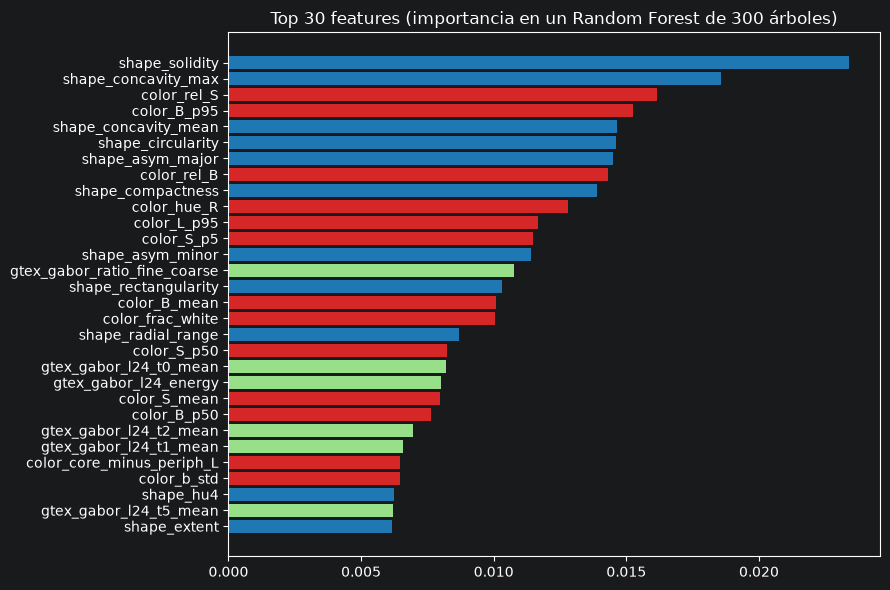

Familias en el top: {'color': 13, 'shape': 11, 'gtex': 6}


In [11]:
def make_selector(k, n_jobs=1):
    """Top-k features según la importancia (Gini) de un Random Forest."""
    est = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
                                 random_state=SEED, n_jobs=n_jobs)
    # est = ExtraTreesClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
    #                            random_state=SEED, n_jobs=n_jobs)          # alternativa más rápida
    return SelectFromModel(est, max_features=k, threshold=-np.inf)


# lista de features elegidas con all train (solo para mostrarla; la CV lo hace dentro de cada fold)
selector = make_selector(K_FEATURES, n_jobs=N_JOBS).fit(Xtr_i, ytr)
sel_imp = pd.Series(selector.estimator_.feature_importances_, index=FEATS).sort_values(ascending=False)
SELECTED = list(sel_imp.index[:K_FEATURES])
sel_imp.head(K_FEATURES).rename("importancia").to_csv(OUT_DIR / "selected_features.csv")

top = sel_imp.head(K_FEATURES)[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color=[FAM_COLOR[family(c)] for c in top.index])
plt.title(f"Top {K_FEATURES} features (importancia en un Random Forest de 300 árboles)")
plt.tight_layout(); plt.show()
print("Familias en el top:", pd.Series([family(c) for c in SELECTED]).value_counts().to_dict())

## 4. Baseline y otros modelos

- **Imputación** (mediana) → **selección top-K** (opcional) → **transformación cuantil a normal** (solo en modelos que
  la necesitan; las features tienen colas muy pesadas) → modelo.
- **Baseline**: regresión logística. `Dummy` es el suelo (AUC 0.5). Modelos: LogReg, KNN, SVM-RBF, árbol, Random Forest,
  HistGradientBoosting y **XGBoost** (si está instalado).
- Métricas en CV: AUC, balanced accuracy, F1 y **recall de `others`** (clase positiva = 1).
- Todos con hiperparámetros razonables por defecto, sin ajuste fino.

**Paralelización** (`N_JOBS` = cores − 2). Es la misma CV de antes (mismos folds y mismo pipeline), organizada para no repetir trabajo:
1. La imputación y la selección top-K se ajustan **una vez por fold** (solo con el train del fold) y se reutilizan
   en todos los modelos; antes se repetían para cada modelo, aunque salían idénticas.
2. Todos los pares **modelo × fold** se entrenan a la vez, repartidos entre los cores. Cada modelo usa 1 core
   (`n_jobs=1`) para no pisarse con el paralelismo de fuera.

In [12]:
MODELS = {   # nombre: (estimador, ¿necesita escalado?)
    "Dummy": (DummyClassifier(strategy="prior"), False),
    "LogReg (baseline)": (LogisticRegression(C=0.5, max_iter=3000), True),
    "KNN": (KNeighborsClassifier(n_neighbors=15), True),
    "SVM-RBF": (SVC(C=1.0, gamma="scale"), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED), False),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=1), False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=4,
                                                           early_stopping=False, random_state=SEED), False),
}
if XGBClassifier is not None:
    MODELS["XGBoost"] = (XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5, min_child_weight=3,
                                       subsample=0.8, colsample_bytree=0.5, reg_lambda=1.0, tree_method="hist",
                                       eval_metric="logloss", n_jobs=1, random_state=SEED), False)
SCORING = ["auc", "bal_acc", "f1", "recall_others"]


def make_prep(k, n_jobs=1):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if k:
        steps.append(("sel", make_selector(k, n_jobs=n_jobs)))
    return Pipeline(steps)


def make_head(model, scale):
    steps = [("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED))] if scale else []
    return Pipeline(steps + [("clf", clone(model))])


def make_pipe(model, scale, k):
    return Pipeline(make_prep(k).steps + make_head(model, scale).steps)


def get_score(est, X):
    return est.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X)


def fold_metrics(y, s, pred):
    return {"auc": roc_auc_score(y, s), "bal_acc": balanced_accuracy_score(y, pred),
            "f1": f1_score(y, pred), "recall_others": recall_score(y, pred)}


def _prep_fold(X, y, a, b, k, n_jobs=1):
    """Imputación (+ top-K) ajustada solo con el train del fold."""
    warnings.filterwarnings("ignore")
    p = make_prep(k, n_jobs=n_jobs).fit(X[a], y[a])
    return p.transform(X[a]), p.transform(X[b])


def _eval_fold(model, scale, X, y, a, b, prepped=None):
    warnings.filterwarnings("ignore")
    if prepped is None:                       # sin top-K la imputación es instantánea: se hace aquí mismo
        prepped = _prep_fold(X, y, a, b, None)
    Xa, Xb = prepped
    m = make_head(model, scale).fit(Xa, y[a])
    test = fold_metrics(y[b], get_score(m, Xb), m.predict(Xb))      # fold de validación (no visto)
    train = fold_metrics(y[a], get_score(m, Xa), m.predict(Xa))     # el mismo train del fold (para ver overfitting)
    return test | {f"train_{key}": v for key, v in train.items()}


def run_cv_many(subsets, k, models=MODELS, return_raw=False):
    """CV de varios subconjuntos de features x varios modelos, todo en paralelo.
    subsets: {nombre: X}. Devuelve una tabla indexada por (subconjunto, modelo) con media ± std de cada métrica."""
    y = ytr
    folds = list(skf.split(np.zeros(len(y)), y))           # mismos folds que antes (solo dependen de y)
    Xs = {n: np.asarray(X, dtype=np.float64) for n, X in subsets.items()}
    prepped = {}
    if k:                                                  # 1) top-K una vez por (subconjunto, fold)
        keys = [(n, f) for n in Xs for f in range(len(folds))]
        inner = max(1, N_JOBS // len(keys))                # cores sobrantes -> árboles del RF selector en paralelo
        out = Parallel(n_jobs=min(N_JOBS, len(keys)))(
            delayed(_prep_fold)(Xs[n], y, *folds[f], k, inner) for n, f in keys)
        prepped = dict(zip(keys, out))
    jobs = [(n, m, f) for n in Xs for m in models for f in range(len(folds))]   # 2) todos los modelo x fold a la vez
    res = Parallel(n_jobs=N_JOBS)(
        delayed(_eval_fold)(models[m][0], models[m][1], None if k else Xs[n], y, *folds[f], prepped.get((n, f)))
        for n, m, f in jobs)
    df = pd.DataFrame(res).assign(subset=[j[0] for j in jobs], model=[j[1] for j in jobs])
    g = df.groupby(["subset", "model"], sort=False)[SCORING]
    mean, std = g.mean(), g.std(ddof=0)
    table = pd.DataFrame({m: mean[m].map("{:.3f}".format) + " ± " + std[m].map("{:.3f}".format) for m in SCORING})
    table["_auc"] = mean["auc"]
    return (table, df) if return_raw else table


def run_cv(X, k, models=MODELS, return_raw=False):
    table, raw = run_cv_many({"X": X}, k, models, return_raw=True)
    table = table.droplevel("subset").sort_values("_auc", ascending=False)
    return (table, raw) if return_raw else table


print(f"CV {CV_FOLDS} folds en train ({len(Xtr)} imágenes), {len(MODELS)} modelos, N_JOBS = {N_JOBS}\n")
res_all, raw_all = run_cv(Xtr, k=None, return_raw=True)
print(f"--- TODAS las features ({len(FEATS)}) ---")
print(res_all.drop(columns="_auc").to_string(), "\n")

res_top, raw_top = run_cv(Xtr, k=K_FEATURES, return_raw=True)
print(f"--- TOP-{K_FEATURES} (selección dentro de cada fold) ---")
print(res_top.drop(columns="_auc").to_string())

res_all.drop(columns="_auc").to_csv(OUT_DIR / "cv_all_features.csv")
res_top.drop(columns="_auc").to_csv(OUT_DIR / f"cv_top{K_FEATURES}.csv")

CV 5 folds en train (15195 imágenes), 8 modelos, N_JOBS = 26

--- TODAS las features (420) ---
                                auc        bal_acc             f1  recall_others
model                                                                           
XGBoost               0.929 ± 0.005  0.855 ± 0.007  0.852 ± 0.008  0.849 ± 0.012
SVM-RBF               0.923 ± 0.006  0.846 ± 0.007  0.843 ± 0.007  0.840 ± 0.010
HistGradientBoosting  0.919 ± 0.004  0.840 ± 0.003  0.837 ± 0.003  0.835 ± 0.009
Random Forest         0.912 ± 0.006  0.833 ± 0.009  0.829 ± 0.009  0.825 ± 0.011
LogReg (baseline)     0.903 ± 0.005  0.824 ± 0.007  0.821 ± 0.007  0.820 ± 0.010
KNN                   0.891 ± 0.003  0.814 ± 0.005  0.812 ± 0.005  0.815 ± 0.008
Decision Tree         0.843 ± 0.003  0.777 ± 0.003  0.773 ± 0.005  0.774 ± 0.012
Dummy                 0.500 ± 0.000  0.500 ± 0.000  0.000 ± 0.000  0.000 ± 0.000 

--- TOP-30 (selección dentro de cada fold) ---
                                auc        bal

### ¿Hay overfitting? Train vs CV
Para cada modelo y fold se mide también el rendimiento sobre **el mismo train con el que se ha entrenado** (el 80 % del fold)
y se compara con el fold de validación. Todo sale de la celda anterior (no se entrena nada nuevo).

- `gap` = train − CV. Un gap grande indica que el modelo memoriza train.
- En Random Forest es normal que train esté cerca de 1.0 (los árboles casi memorizan los datos) aunque generalice bien:
  lo que manda es la CV, y que **suba la CV** al regularizar, no solo que baje el gap.
- KNN, LogReg y SVM deberían tener gaps pequeños; si son grandes, hay que regularizar más (C menor, más vecinos...).

--- TODAS las features (420): train vs CV ---
                      train_auc  cv_auc  gap_auc  train_bal_acc  cv_bal_acc  gap_bal_acc  train_recall  cv_recall
model                                                                                                            
XGBoost                   0.999   0.929    0.070          0.985       0.855        0.131         0.985      0.849
SVM-RBF                   0.957   0.923    0.035          0.889       0.846        0.043         0.882      0.840
HistGradientBoosting      0.974   0.919    0.056          0.911       0.840        0.071         0.906      0.835
Random Forest             1.000   0.912    0.088          0.992       0.833        0.159         0.992      0.825
LogReg (baseline)         0.919   0.903    0.015          0.839       0.824        0.015         0.836      0.820
KNN                       0.919   0.891    0.029          0.836       0.814        0.022         0.836      0.815
Decision Tree             0.868   0.843   

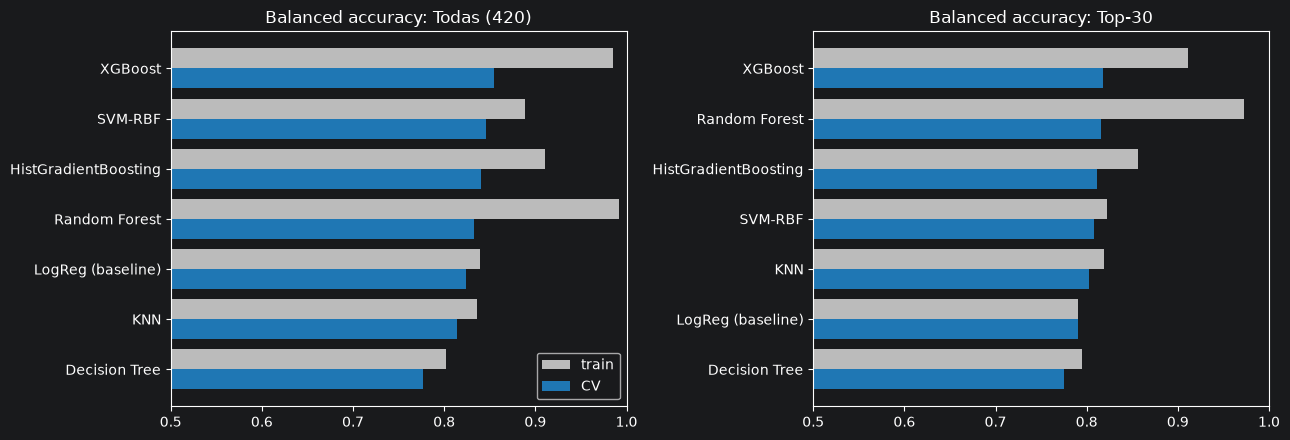

In [13]:
def train_vs_cv(raw):
    g = raw.groupby("model", sort=False)
    t = pd.DataFrame({"train_auc": g["train_auc"].mean(), "cv_auc": g["auc"].mean(),
                      "train_bal_acc": g["train_bal_acc"].mean(), "cv_bal_acc": g["bal_acc"].mean(),
                      "train_recall": g["train_recall_others"].mean(), "cv_recall": g["recall_others"].mean()})
    t.insert(2, "gap_auc", t["train_auc"] - t["cv_auc"])
    t.insert(5, "gap_bal_acc", t["train_bal_acc"] - t["cv_bal_acc"])
    return t.sort_values("cv_auc", ascending=False).round(3)


ovf_all, ovf_top = train_vs_cv(raw_all), train_vs_cv(raw_top)
print(f"--- TODAS las features ({len(FEATS)}): train vs CV ---")
print(ovf_all.to_string(), "\n")
print(f"--- TOP-{K_FEATURES}: train vs CV ---")
print(ovf_top.to_string())
ovf_all.to_csv(OUT_DIR / "train_vs_cv_all_features.csv")
ovf_top.to_csv(OUT_DIR / f"train_vs_cv_top{K_FEATURES}.csv")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, (title, t) in zip(axs, [(f"Todas ({len(FEATS)})", ovf_all), (f"Top-{K_FEATURES}", ovf_top)]):
    t = t.drop(index="Dummy", errors="ignore")[::-1]
    yy = np.arange(len(t))
    ax.barh(yy + 0.2, t["train_bal_acc"], 0.4, label="train", color="#bbbbbb")
    ax.barh(yy - 0.2, t["cv_bal_acc"], 0.4, label="CV", color="#1f77b4")
    ax.set_yticks(yy, t.index); ax.set_xlim(0.5, 1.0); ax.set_title(f"Balanced accuracy: {title}")
axs[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 5. Ablación por familias
Mismo modelo (Random Forest, sin selección) con cada familia sola y combinadas. Sirve para ver cuánto aporta
cada una y si son complementarias.

Ojo con las familias de **imagen entera** (`gcolor`, `gtex`): se calculan sobre todos los píxeles, así que pueden
captar la cámara, la iluminación o el fondo en vez de la lesión. Compara "lesión" frente a "imagen entera" y frente a "todas".

In [14]:
fam_cols = {f: [c for c in FEATS if family(c) == f] for f in ["shape", "color", "tex", "gcolor", "gtex"]}
lesion = fam_cols["shape"] + fam_cols["color"] + fam_cols["tex"]
imagen = fam_cols["gcolor"] + fam_cols["gtex"]
subsets = {"solo forma": fam_cols["shape"], "solo color": fam_cols["color"], "solo textura": fam_cols["tex"],
           "solo gcolor": fam_cols["gcolor"], "solo gtex": fam_cols["gtex"],
           "forma + color": fam_cols["shape"] + fam_cols["color"], "color + textura": fam_cols["color"] + fam_cols["tex"],
           "lesión (shape+color+tex)": lesion, "imagen entera (gcolor+gtex)": imagen,
           "todas": FEATS}
rf = {"Random Forest": MODELS["Random Forest"]}
# todos los subconjuntos x folds en paralelo (antes iban uno detrás de otro)
abl = run_cv_many({name: Xtr[cols] for name, cols in subsets.items()}, k=None, models=rf).droplevel("model")
abl.insert(0, "n_features", [len(c) for c in subsets.values()])
print(abl.drop(columns="_auc").to_string())
abl.drop(columns="_auc").to_csv(OUT_DIR / "ablation_families.csv")

                             n_features            auc        bal_acc             f1  recall_others
subset                                                                                             
solo forma                           76  0.840 ± 0.005  0.769 ± 0.005  0.763 ± 0.005  0.757 ± 0.006
solo color                           83  0.898 ± 0.005  0.819 ± 0.005  0.816 ± 0.005  0.816 ± 0.010
solo textura                         95  0.849 ± 0.007  0.771 ± 0.010  0.766 ± 0.010  0.760 ± 0.010
solo gcolor                          71  0.883 ± 0.007  0.804 ± 0.008  0.798 ± 0.007  0.788 ± 0.008
solo gtex                            95  0.874 ± 0.004  0.799 ± 0.004  0.794 ± 0.004  0.788 ± 0.005
forma + color                       159  0.897 ± 0.006  0.819 ± 0.008  0.817 ± 0.008  0.819 ± 0.010
color + textura                     178  0.904 ± 0.005  0.826 ± 0.004  0.823 ± 0.005  0.822 ± 0.010
lesión (shape+color+tex)            254  0.901 ± 0.005  0.823 ± 0.006  0.820 ± 0.006  0.822 ± 0.010


## 6. Evaluación final en val
Cada modelo se entrena con **todo train** (con la selección top-K dentro del pipeline) y se evalúa una sola vez en val.
Umbral de decisión por defecto (0.5). El IC del AUC se obtiene por bootstrap sobre las imágenes de val.

In [15]:
def boot_ci(y, s, n=1000, seed=0):
    rng, vals = np.random.RandomState(seed), []
    for _ in range(n):
        i = rng.choice(len(y), len(y), replace=True)
        if len(np.unique(y[i])) == 2:
            vals.append(roc_auc_score(y[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])


def _fit_head(model, scale, X, y):
    warnings.filterwarnings("ignore")
    return make_head(model, scale).fit(X, y)


# imputación + top-K con todo train UNA vez (es la misma para todos los modelos), después los modelos en paralelo
prep = make_prep(K_FEATURES, n_jobs=N_JOBS).fit(Xtr, ytr)
Xtr_s, Xva_s = prep.transform(Xtr), prep.transform(Xva)
heads = Parallel(n_jobs=N_JOBS)(delayed(_fit_head)(est, scale, Xtr_s, ytr) for est, scale in MODELS.values())

fitted, rows, scores, preds = {}, [], {}, {}
for name, head in zip(MODELS, heads):
    pipe = Pipeline(prep.steps + head.steps)          # pipeline completo ya entrenado (acepta las 420 columnas)
    s, pred = get_score(pipe, Xva), pipe.predict(Xva)
    lo, hi = boot_ci(yva, s)
    fitted[name], scores[name], preds[name] = pipe, s, pred
    rows.append({"modelo": name, "AUC": roc_auc_score(yva, s), "AUC IC95%": f"[{lo:.3f}, {hi:.3f}]",
                 "bal_acc": balanced_accuracy_score(yva, pred), "F1": f1_score(yva, pred),
                 "recall_others": recall_score(yva, pred), "precision_others": precision_score(yva, pred, zero_division=0)})
val_res = pd.DataFrame(rows).set_index("modelo").sort_values("AUC", ascending=False)
print(f"Val ({len(Xva)} imágenes), modelos con top-{K_FEATURES}:\n")
print(val_res.round(3).to_string())
val_res.round(4).to_csv(OUT_DIR / f"val_top{K_FEATURES}.csv")

Val (3796 imágenes), modelos con top-30:

                        AUC       AUC IC95%  bal_acc     F1  recall_others  precision_others
modelo                                                                                      
XGBoost               0.901  [0.892, 0.910]    0.819  0.813          0.801             0.826
Random Forest         0.900  [0.890, 0.909]    0.823  0.817          0.804             0.830
HistGradientBoosting  0.896  [0.886, 0.905]    0.813  0.807          0.795             0.821
SVM-RBF               0.893  [0.882, 0.902]    0.820  0.814          0.801             0.828
KNN                   0.882  [0.871, 0.892]    0.805  0.800          0.797             0.804
LogReg (baseline)     0.867  [0.856, 0.878]    0.794  0.787          0.771             0.803
Decision Tree         0.846  [0.835, 0.857]    0.779  0.779          0.795             0.764
Dummy                 0.500  [0.500, 0.500]    0.500  0.000          0.000             0.000


Mejor modelo en CV: XGBoost


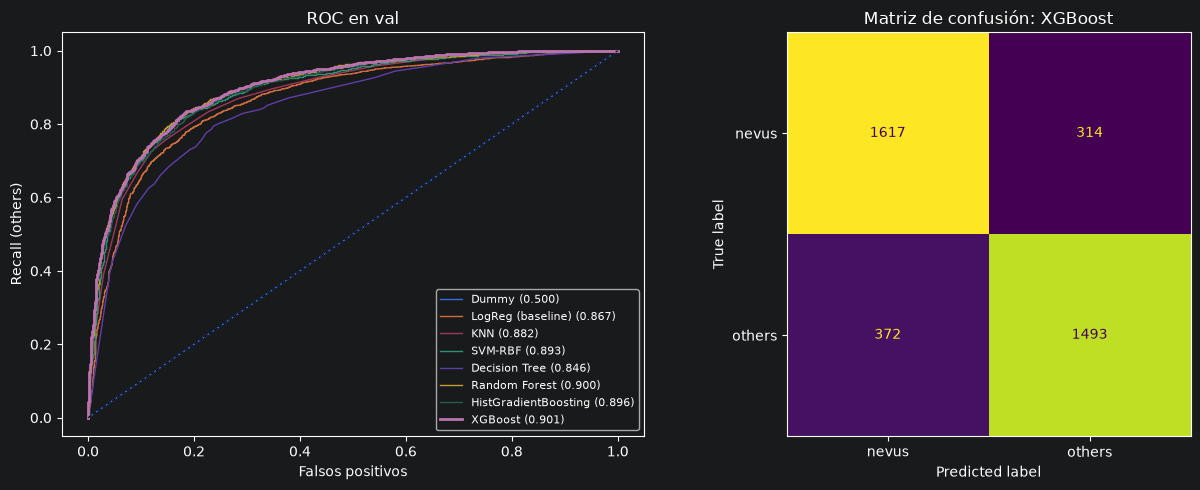

In [16]:
best = res_top.index[0]          # mejor modelo según AUC en CV (no según val)
print("Mejor modelo en CV:", best)

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(yva, s)
    axs[0].plot(fpr, tpr, lw=2 if name == best else 1, label=f"{name} ({roc_auc_score(yva, s):.3f})")
axs[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axs[0].set(xlabel="Falsos positivos", ylabel="Recall (others)", title="ROC en val"); axs[0].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(yva, fitted[best].predict(Xva), display_labels=["nevus", "others"],
                                        ax=axs[1], colorbar=False)
axs[1].set_title(f"Matriz de confusión: {best}")
plt.tight_layout(); plt.show()

### Matriz de confusión de todos los modelos (val)

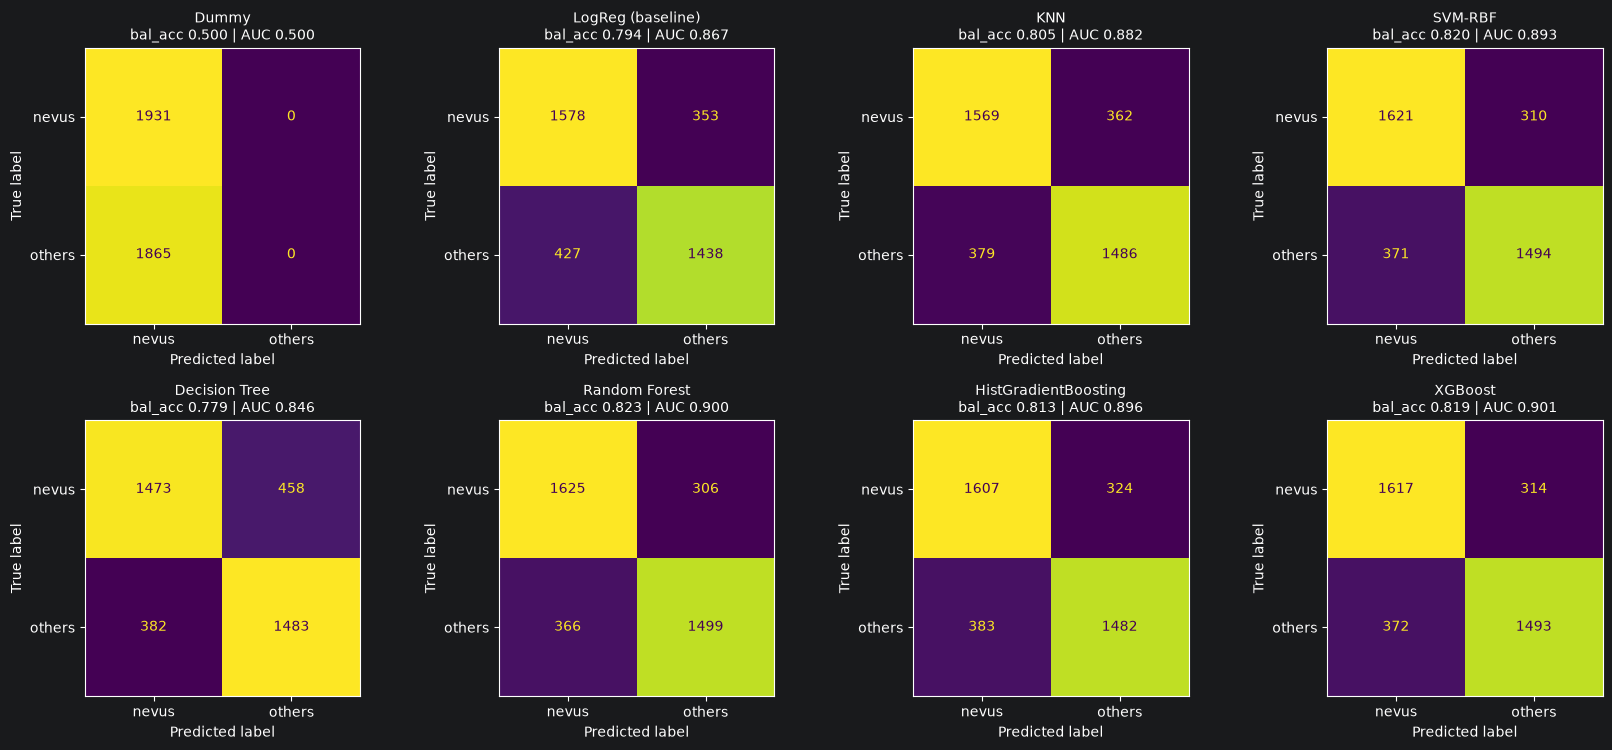

In [17]:
names = list(fitted)
nc = 4
nr = int(np.ceil(len(names) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(4.2 * nc, 3.8 * nr), squeeze=False)
for ax, name in zip(axs.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(yva, preds[name], display_labels=["nevus", "others"],
                                            ax=ax, colorbar=False)
    ax.set_title(f"{name}\nbal_acc {val_res.loc[name, 'bal_acc']:.3f} | AUC {val_res.loc[name, 'AUC']:.3f}", fontsize=10)
for ax in axs.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Guardar los modelos
Se guarda cada modelo final (entrenado con todo train) en `ml_results_completes/models/` como un `.joblib` con el **pipeline completo**
(imputación → selección → escalado → modelo), más una copia del mejor como `best_model.joblib` y un `models_info.json`
con la lista de features (en orden), las etiquetas, las métricas en val y las versiones de las librerías.
(`*.joblib` está en el `.gitignore`: no se suben a GitHub.)

Para usarlos después (por ejemplo con las features del test), hacen falta **las mismas versiones** de sklearn / xgboost:
```python
import json, joblib, pandas as pd
d = ROOT / "ml" / "ml_results_completes" / "models"
info = json.load(open(d / "models_info.json", encoding="utf-8"))
model = joblib.load(d / "best_model.joblib")
X_test = pd.read_csv("features_test.csv")[info["features"]]     # mismas columnas, mismo orden
pred = model.predict(X_test)                                    # 0 = nevus, 1 = others; model.predict_proba(X_test)[:, 1] = probabilidad de others
```

In [18]:
TASK = "binary"
LABELS = {0: "nevus", 1: "others"}
SELECTION = f"top-{K_FEATURES} (Random Forest, SelectFromModel)"

import json
import platform
from datetime import datetime

import joblib
import sklearn

MODEL_DIR = OUT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
slug = lambda s: "".join(ch if ch.isalnum() else "_" for ch in s).strip("_").lower()

# cada archivo es el pipeline COMPLETO ya entrenado con todo train:
# imputación -> [selección top-K] -> [escalado] -> modelo. Recibe las features crudas (FEATS, en ese orden).
saved = {}
for name, pipe in fitted.items():
    if name == "Dummy":
        continue
    path = MODEL_DIR / f"{slug(name)}.joblib"
    joblib.dump(pipe, path, compress=3)
    saved[name] = path.name
joblib.dump(fitted[best], MODEL_DIR / "best_model.joblib", compress=3)

# comprobación: el modelo recargado predice exactamente lo mismo en val
assert (joblib.load(MODEL_DIR / "best_model.joblib").predict(Xva) == preds[best]).all()

try:
    import xgboost
    xgb_version = xgboost.__version__
except Exception:
    xgb_version = None

info = {
    "task": TASK,
    "created": datetime.now().isoformat(timespec="seconds"),
    "best_model": best,
    "files": {**saved, "best": "best_model.joblib"},
    "labels": LABELS,
    "feature_selection": SELECTION,
    "n_features_in": len(FEATS),
    "features": FEATS,                                   # columnas de entrada, en este orden
    "train_csv": str(TRAIN_CSV),
    "val_metrics": val_res.reset_index().to_dict(orient="records"),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgb_version,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
(MODEL_DIR / "models_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

print(f"Modelos guardados en {MODEL_DIR}  (mejor: {best} -> best_model.joblib)\n")
for f in sorted(MODEL_DIR.glob("*")):
    print(f"  {f.name:<35s} {f.stat().st_size / 1e6:7.1f} MB")

Modelos guardados en C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\ml\ml_results_completes2\models  (mejor: XGBoost -> best_model.joblib)

  best_model.joblib                      12.1 MB
  decision_tree.joblib                   11.7 MB
  histgradientboosting.joblib            12.0 MB
  knn.joblib                             15.0 MB
  logreg__baseline.joblib                11.7 MB
  models_info.json                        0.0 MB
  random_forest.joblib                   25.3 MB
  svm_rbf.joblib                         13.3 MB
  xgboost.joblib                         12.1 MB


### ¿Qué features usa realmente el mejor modelo?
Importancia por permutación en val (cuánto cae el AUC al barajar cada feature). Solo se permutan las top-K que el modelo
usa de verdad (las demás tienen importancia 0 por construcción), así va mucho más rápido.
Sirve también para vigilar que no dominen features raras (por ejemplo del color global, `gcolor_`/`gtex_`) que podrían
delatar la cámara y no la lesión.

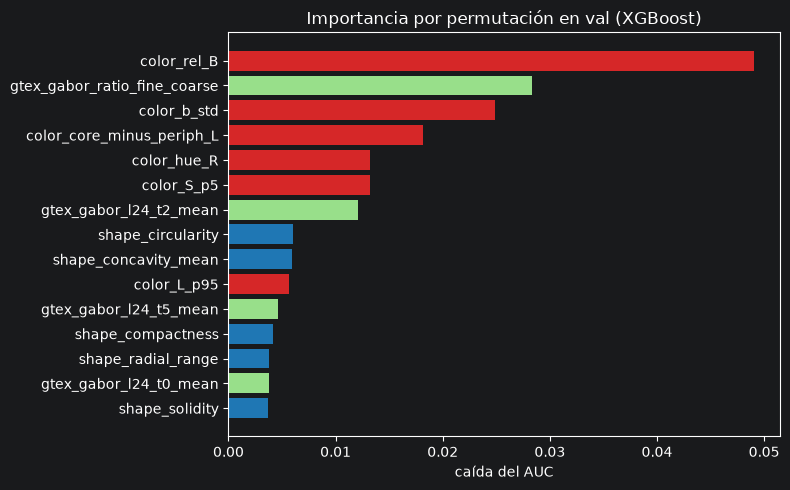

In [19]:
pipe = fitted[best]
sel = pipe.named_steps["sel"].get_support()
Xva_sel = pipe.named_steps["imp"].transform(Xva)[:, sel]          # val imputada, solo las top-K
pi = permutation_importance(pipe[2:], Xva_sel, yva, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=N_JOBS)
pi = pd.Series(pi.importances_mean, index=np.array(FEATS)[sel]).sort_values(ascending=False).head(15)[::-1]
plt.figure(figsize=(8, 5))
plt.barh(pi.index, pi.values, color=[FAM_COLOR[family(c)] for c in pi.index])
plt.title(f"Importancia por permutación en val ({best})")
plt.xlabel("caída del AUC"); plt.tight_layout(); plt.show()

In [20]:
man = pd.read_csv(ROOT / "processed" / "manifest.csv").set_index("name")
cols = ["orig_h", "orig_w"]
m_tr, m_va = man.reindex(tr["name"])[cols], man.reindex(va["name"])[cols]
g = HistGradientBoostingClassifier(random_state=SEED).fit(m_tr, ytr)
print("AUC solo con el tamaño original:", roc_auc_score(yva, g.predict_proba(m_va)[:, 1]))

AUC solo con el tamaño original: 0.6760477769925707


In [21]:
pred = fitted[best].predict(Xva)
tmp = va[["subtype"]].assign(acierto=(pred == yva))
print(tmp.groupby("subtype")["acierto"].agg(["mean", "size"]).round(3))

          mean  size
subtype             
ack      0.954   130
bcc      0.922   498
bkl      0.720   393
def      0.657    35
mel      0.721   678
nev      0.837  1931
scc      0.947    94
vac      0.703    37


In [22]:
sz = man.reindex(va["name"])[["orig_h", "orig_w"]].reset_index(drop=True)
va_sz = va[["name", "class"]].reset_index(drop=True).join(sz)
va_sz["res"] = va_sz["orig_w"].astype(str) + "x" + va_sz["orig_h"].astype(str)

print(pd.crosstab(va_sz["res"], va_sz["class"]).sort_values("nevus", ascending=False).head(10))

s, rows = scores[best], []
for res, g in va_sz.groupby("res"):
    y = yva[g.index]
    if len(g) >= 30 and 0 < y.mean() < 1:
        rows.append((res, len(g), round(y.mean(), 2), roc_auc_score(y, s[g.index])))
print(pd.DataFrame(rows, columns=["res", "n", "frac_others", "AUC"]).round(3))

class      nevus  others
res                     
600x450      983     495
1024x1024    645    1226
1024x680      91      72
1024x768      91      30
1024x682      27       1
1024x685      19       7
1024x679      12       4
1024x683       7       2
1024x681       7       2
767x576        7       3
         res     n  frac_others    AUC
0  1024x1024  1871         0.66  0.904
1   1024x680   163         0.44  0.806
2   1024x768   121         0.25  0.792
3    600x450  1478         0.33  0.897


In [23]:
# AUC solo melanoma vs nevus
m = va["subtype"].isin(["mel", "nev"]).values
print("AUC mel vs nev:", roc_auc_score(yva[m], scores[best][m]))

# sensibilidad de others a especificidad fija de nevus
fpr, tpr, _ = roc_curve(yva, scores[best])
for sp in [0.80, 0.90, 0.95]:
    print(f"especificidad {sp:.0%}: sensibilidad {tpr[np.searchsorted(fpr, 1 - sp, side='right') - 1]:.3f}")

AUC mel vs nev: 0.8653073819638901
especificidad 80%: sensibilidad 0.840
especificidad 90%: sensibilidad 0.711
especificidad 95%: sensibilidad 0.591
